In [12]:
import pandas as pd
import matplotlib as mpl
import numpy as np

In [13]:
path = "./"

df_ts = pd.read_csv(f"{path}/timeseries.csv")
df_ts

,Date,Close,Start,High,Low,Volume
0,2015-07-02,10100,10850,10900,10000,137977
1,2016-06-29,10700,10550,10900,9990,170253
2,2017-06-28,10400,10900,10950,10150,155769
3,2018-06-27,10900,10800,11050,10500,133548
4,2019-06-26,10800,10900,11000,10700,63039


In [14]:
#Date열을 datetime형으로 형변환
ts_date = pd.to_datetime(df_ts.Date)
ts_date

0   2015-07-02
1   2016-06-29
2   2017-06-28
3   2018-06-27
4   2019-06-26
Name: Date, dtype: datetime64[us]

In [15]:
#일 주기
ts_day = ts_date.dt.to_period(freq="D")
ts_day

0    2015-07-02
1    2016-06-29
2    2017-06-28
3    2018-06-27
4    2019-06-26
Name: Date, dtype: period[D]

In [16]:
#달 주기
ts_mon = ts_date.dt.to_period(freq="M")
ts_mon

0    2015-07
1    2016-06
2    2017-06
3    2018-06
4    2019-06
Name: Date, dtype: period[M]

In [17]:
#연 주기
ts_yrs = ts_date.dt.to_period(freq="Y")
#키 A는 안됨
ts_yrs

0    2015
1    2016
2    2017
3    2018
4    2019
Name: Date, dtype: period[Y-DEC]

In [18]:
#datetime형 데프를 새 열에 추가
df_ts["New Date"] = ts_date
df_ts.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      5 non-null      str           
 1   Close     5 non-null      int64         
 2   Start     5 non-null      int64         
 3   High      5 non-null      int64         
 4   Low       5 non-null      int64         
 5   Volume    5 non-null      int64         
 6   New Date  5 non-null      datetime64[us]
dtypes: datetime64[us](1), int64(5), str(1)
memory usage: 412.0 bytes


In [19]:
#기존 열 Date 삭제
df_ts.drop("Date", axis=1, inplace=True)
#inplace 키워드가 지원 종료될 거라네

/tmp/ipykernel_14118/2333286453.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_ts.drop("Date", axis=1, inplace=True)


In [20]:
df_ts.set_index("New Date", inplace=True)
df_ts

/tmp/ipykernel_14118/1414880430.py:1: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_ts.set_index("New Date", inplace=True)


,Close,Start,High,Low,Volume
New Date,,,,,
2015-07-02,10100,10850,10900,10000,137977
2016-06-29,10700,10550,10900,9990,170253
2017-06-28,10400,10900,10950,10150,155769
2018-06-27,10900,10800,11050,10500,133548
2019-06-26,10800,10900,11000,10700,63039


<Axes: xlabel='New Date'>

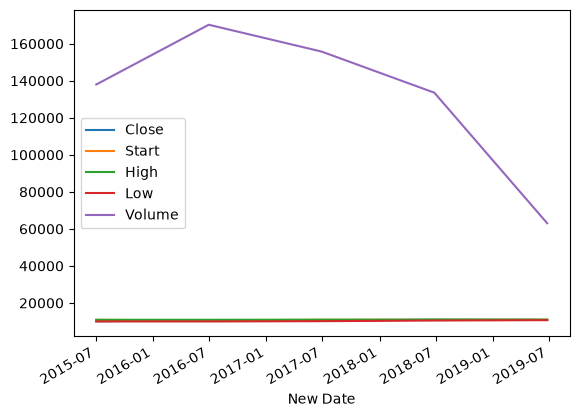

In [21]:
df_ts.plot()

In [22]:
#해당 연월일로부터 +6일까지의 범위
dates = pd.date_range("20200427", periods=6)
df = pd.DataFrame(
    np.random.randn(6, 4),
    index = dates,
    columns = list("ABCD")
)

df

,A,B,C,D
2020-04-27,-1.952444,-0.848203,0.691919,1.057544
2020-04-28,0.034911,1.487579,-0.688665,-0.337360
2020-04-29,-0.324409,-0.421287,0.178033,0.872799
2020-04-30,0.287427,-2.076526,0.394442,-0.005428
2020-05-01,-1.470352,1.675680,1.880717,0.063189
2020-05-02,0.623169,-1.552933,-0.919917,0.096111


In [24]:
df_ts = pd.read_csv(f"{path}/timeseries.csv")
df_ts["New Date"] = ts_date

df_ts["Year"] = df_ts["New Date"].dt.year
df_ts["Month"] = df_ts["New Date"].dt.month
df_ts["Day"] = df_ts["New Date"].dt.day

df_ts

,Date,Close,Start,High,Low,Volume,New Date,Year,Month,Day
0,2015-07-02,10100,10850,10900,10000,137977,2015-07-02,2015,7,2
1,2016-06-29,10700,10550,10900,9990,170253,2016-06-29,2016,6,29
2,2017-06-28,10400,10900,10950,10150,155769,2017-06-28,2017,6,28
3,2018-06-27,10900,10800,11050,10500,133548,2018-06-27,2018,6,27
4,2019-06-26,10800,10900,11000,10700,63039,2019-06-26,2019,6,26


In [25]:
df_ts["Date Year"] = df_ts["New Date"].dt.to_period(freq="Y")
df_ts["Date Month"] = df_ts["New Date"].dt.to_period(freq="M")

df_ts

,Date,Close,Start,High,Low,Volume,New Date,Year,Month,Day,Date Year,Date Month
0,2015-07-02,10100,10850,10900,10000,137977,2015-07-02,2015,7,2,2015,2015-07
1,2016-06-29,10700,10550,10900,9990,170253,2016-06-29,2016,6,29,2016,2016-06
2,2017-06-28,10400,10900,10950,10150,155769,2017-06-28,2017,6,28,2017,2017-06
3,2018-06-27,10900,10800,11050,10500,133548,2018-06-27,2018,6,27,2018,2018-06
4,2019-06-26,10800,10900,11000,10700,63039,2019-06-26,2019,6,26,2019,2019-06


In [26]:
df_ts.set_index("New Date", inplace=True)
df_ts

/tmp/ipykernel_14118/1414880430.py:1: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_ts.set_index("New Date", inplace=True)


,Date,Close,Start,High,Low,Volume,Year,Month,Day,Date Year,Date Month
New Date,,,,,,,,,,,
2015-07-02,2015-07-02,10100,10850,10900,10000,137977,2015,7,2,2015,2015-07
2016-06-29,2016-06-29,10700,10550,10900,9990,170253,2016,6,29,2016,2016-06
2017-06-28,2017-06-28,10400,10900,10950,10150,155769,2017,6,28,2017,2017-06
2018-06-27,2018-06-27,10900,10800,11050,10500,133548,2018,6,27,2018,2018-06
2019-06-26,2019-06-26,10800,10900,11000,10700,63039,2019,6,26,2019,2019-06


In [27]:
df_ts.loc["2015-07"]

,Date,Close,Start,High,Low,Volume,Year,Month,Day,Date Year,Date Month
New Date,,,,,,,,,,,
2015-07-02,2015-07-02,10100,10850,10900,10000,137977,2015,7,2,2015,2015-07


In [28]:
df_ts["2015-06-25" : "2018-06-20"]

,Date,Close,Start,High,Low,Volume,Year,Month,Day,Date Year,Date Month
New Date,,,,,,,,,,,
2015-07-02,2015-07-02,10100,10850,10900,10000,137977,2015,7,2,2015,2015-07
2016-06-29,2016-06-29,10700,10550,10900,9990,170253,2016,6,29,2016,2016-06
2017-06-28,2017-06-28,10400,10900,10950,10150,155769,2017,6,28,2017,2017-06


In [29]:
today = pd.to_datetime("2026-10-28") #오늘 자 기준
df_ts["Time Diff"] = today - df_ts.index

df_ts

,Date,Close,Start,High,Low,Volume,Year,Month,Day,Date Year,Date Month,Time Diff
New Date,,,,,,,,,,,,
2015-07-02,2015-07-02,10100,10850,10900,10000,137977,2015,7,2,2015,2015-07,4136 days
2016-06-29,2016-06-29,10700,10550,10900,9990,170253,2016,6,29,2016,2016-06,3773 days
2017-06-28,2017-06-28,10400,10900,10950,10150,155769,2017,6,28,2017,2017-06,3409 days
2018-06-27,2018-06-27,10900,10800,11050,10500,133548,2018,6,27,2018,2018-06,3045 days
2019-06-26,2019-06-26,10800,10900,11000,10700,63039,2019,6,26,2019,2019-06,2681 days
